# 03. Training from Scratch

## 실험 목적

ImageNet 사전학습 가중치를 사용하지 않은 ResNet18을
학습하여 행동 이미지 분류의 Scratch 기준선을 구축한다.

동일한 데이터 분할 및 전처리 조건에서 Feature Extraction,
Full Fine-tuning과 비교하기 위한 기준 성능과 학습 효율을 확보한다.

- Model: ResNet18 (weights=None)
- Training Strategy: Training from Scratch
- Primary Metric: Validation Macro F1
- Checkpoint Selection: Best Validation Macro F1

## 1. 라이브러리 및 전처리 모듈 불러오기

In [26]:
# 기본 라이브러리
import sys
import time
from pathlib import Path

# 데이터 처리
import numpy as np
import pandas as pd

# 시각화
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim

# 모델
from torchvision.models import resnet18

# 평가 지표
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 프로젝트 루트 경로 설정
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# 모듈 검색 경로에 프로젝트 루트 추가
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("현재 작업 경로:", Path.cwd())
print("프로젝트 루트:", PROJECT_ROOT)
print(
    "전처리 모듈 존재 여부:",
    (PROJECT_ROOT / "src" / "preprocessing.py").exists()
)

from src.preprocessing import (
    set_seed,
    get_dataloaders,
    SEED,
    IMAGE_SIZE,
    BATCH_SIZE,
    NUM_CLASSES
)

print("전처리 모듈 import 완료")
print("SEED:", SEED)
print("IMAGE_SIZE:", IMAGE_SIZE)
print("BATCH_SIZE:", BATCH_SIZE)
print("NUM_CLASSES:", NUM_CLASSES)

현재 작업 경로: c:\Users\yunha\human-action-classification\notebooks
프로젝트 루트: c:\Users\yunha\human-action-classification
전처리 모듈 존재 여부: True
전처리 모듈 import 완료
SEED: 42
IMAGE_SIZE: 224
BATCH_SIZE: 32
NUM_CLASSES: 8


## 2. 실험 설정 및 GPU 확인

Scratch 기준선 학습에 사용할 하이퍼파라미터를 정의하고,
GPU 사용 가능 여부 및 학습 환경을 확인한다.

In [27]:
# 실험 설정
EXPERIMENT_NAME = "scratch_baseline"
MODEL_NAME = "resnet18"

EPOCHS = 30
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0

# Random Seed 설정
set_seed(SEED)

# 학습 장치 설정
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 학습 환경 확인
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("CUDA Version:", torch.version.cuda)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )
print()
print("===== Experiment Configuration =====")
print("Experiment:", EXPERIMENT_NAME)
print("Model:", MODEL_NAME)
print("Training Strategy: Scratch")
print("Pretrained Weights: None")
print("Seed:", SEED)
print("Image Size:", IMAGE_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Number of Classes:", NUM_CLASSES)
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Weight Decay:", WEIGHT_DECAY)
print("Optimizer: Adam")
print("Loss Function: CrossEntropyLoss")
print("Primary Metric: Macro F1")
print("Device:", device)

PyTorch Version: 2.10.0+cu128
CUDA Available: True
CUDA Version: 12.8
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
GPU Memory: 7.96 GB

===== Experiment Configuration =====
Experiment: scratch_baseline
Model: resnet18
Training Strategy: Scratch
Pretrained Weights: None
Seed: 42
Image Size: 224
Batch Size: 32
Number of Classes: 8
Epochs: 30
Learning Rate: 0.001
Weight Decay: 0.0
Optimizer: Adam
Loss Function: CrossEntropyLoss
Primary Metric: Macro F1
Device: cuda


## 3. DataLoader 불러오기

공통 전처리 모듈을 활용하여 DataLoader를 생성한다.
기존 데이터 분할 및 전처리 조건을 유지하며,
Scratch 기준선 학습에는 Train과 Validation만 사용한다.

In [28]:
# 공통 DataLoader 생성
train_loader, val_loader, test_loader = get_dataloaders()

# 데이터 수 및 Batch 수 확인
print("===== DataLoader Information =====")

print("Train Images:", len(train_loader.dataset))
print("Validation Images:", len(val_loader.dataset))
print("Test Images:", len(test_loader.dataset))

print()

print("Train Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Test Batches:", len(test_loader))

===== DataLoader Information =====
Train Images: 640
Validation Images: 160
Test Images: 1231

Train Batches: 20
Validation Batches: 5
Test Batches: 39


In [29]:
# Train DataLoader에서 하나의 Batch 추출
images, labels = next(iter(train_loader))

print("===== Batch Information =====")

print("Images Shape:", images.shape)
print("Images Dtype:", images.dtype)

print("Labels Shape:", labels.shape)
print("Labels Dtype:", labels.dtype)

print("Label Min:", labels.min().item())
print("Label Max:", labels.max().item())

===== Batch Information =====
Images Shape: torch.Size([32, 3, 224, 224])
Images Dtype: torch.float32
Labels Shape: torch.Size([32])
Labels Dtype: torch.int64
Label Min: 0
Label Max: 7


## 4. ResNet18 Scratch 모델 생성

사전학습 가중치를 사용하지 않은 ResNet18 모델을 생성한다.
모델의 기본 구조와 마지막 FC Layer를 확인한다.

In [30]:
# Scratch 모델 생성
model = resnet18(weights=None)

# 모델 구조 확인
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [31]:
# 기존 분류기 확인
print(model.fc)

print("입력 특징 수:", model.fc.in_features)
print("출력 클래스 수:", model.fc.out_features)

Linear(in_features=512, out_features=1000, bias=True)
입력 특징 수: 512
출력 클래스 수: 1000


## 5. 마지막 FC Layer 수정

기존 ResNet18의 1,000개 클래스 분류기를
우리 데이터셋의 8개 행동 클래스에 맞게 변경한다.

In [32]:
# 기존 FC Layer의 입력 특징 수
in_features = model.fc.in_features

# 8개 클래스에 맞게 FC Layer 교체
model.fc = nn.Linear(in_features, NUM_CLASSES)

# 변경된 FC Layer 확인
print(model.fc)

Linear(in_features=512, out_features=8, bias=True)


In [33]:
# 모델을 학습 장치로 이동
model = model.to(device)

# 모델의 파라미터가 위치한 장치 확인
print("Model Device:", next(model.parameters()).device)

Model Device: cuda:0


## 6. 전체 및 학습 가능한 파라미터 수 확인

모델의 전체 파라미터 수와 학습 가능한 파라미터 수를 확인한다.
이후 Feature Extraction 및 Full Fine-tuning과의
학습 효율 비교에 활용한다.

In [34]:
# 전체 파라미터 수
total_params = sum(
    p.numel() for p in model.parameters()
)

# 학습 가능한 파라미터 수
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

# 고정된 파라미터 수
frozen_params = total_params - trainable_params

# 학습 가능한 파라미터 비율
trainable_ratio = trainable_params / total_params * 100

print("===== Model Parameters =====")
print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print(f"Frozen Parameters: {frozen_params:,}")
print(f"Trainable Ratio: {trainable_ratio:.2f}%")

===== Model Parameters =====
Total Parameters: 11,180,616
Trainable Parameters: 11,180,616
Frozen Parameters: 0
Trainable Ratio: 100.00%


In [35]:
# FC Layer 파라미터 수
fc_params = sum(
    p.numel() for p in model.fc.parameters()
)

# Backbone 파라미터 수
backbone_params = total_params - fc_params

print("===== Parameter Distribution =====")
print(f"Backbone Parameters: {backbone_params:,}")
print(f"FC Parameters: {fc_params:,}")
print(f"Backbone Ratio: {backbone_params / total_params * 100:.4f}%")
print(f"FC Ratio: {fc_params / total_params * 100:.4f}%")

===== Parameter Distribution =====
Backbone Parameters: 11,176,512
FC Parameters: 4,104
Backbone Ratio: 99.9633%
FC Ratio: 0.0367%


## 7. Loss Function 및 Optimizer 설정

다중 클래스 이미지 분류를 위한 CrossEntropyLoss를 정의하고,
전체 모델 파라미터를 학습하기 위한 Adam Optimizer를 설정한다.

In [36]:
# 손실 함수 설정
criterion = nn.CrossEntropyLoss()

print(criterion)

CrossEntropyLoss()


In [37]:
# Optimizer 설정
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0
)


In [38]:
# Optimizer에 등록된 파라미터 수
optimizer_params = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

print("===== Training Configuration =====")
print("Loss Function:", criterion.__class__.__name__)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning Rate:", optimizer.param_groups[0]["lr"])
print("Weight Decay:", optimizer.param_groups[0]["weight_decay"])
print(f"Optimizer Parameters: {optimizer_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")
print("Parameter Count Match:", optimizer_params == trainable_params)

===== Training Configuration =====
Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001
Weight Decay: 0.0
Optimizer Parameters: 11,180,616
Trainable Parameters: 11,180,616
Parameter Count Match: True


## 8. Train 함수 구현

전체 Train 데이터를 Batch 단위로 학습하는 함수를 구현한다.
각 Batch에서 순전파, 손실 계산, 역전파 및 가중치 업데이트를 수행하고,
Epoch 단위의 평균 Loss, Accuracy, Macro F1을 반환한다.

In [39]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    # 학습 모드 설정
    model.train()

    # Epoch 결과 기록용 변수
    running_loss = 0.0
    all_preds = []
    all_labels = []

    # Batch 단위 학습
    for images, labels in dataloader:

        # GPU로 데이터 이동
        images = images.to(device)
        labels = labels.to(device)

        # 기울기 초기화
        optimizer.zero_grad()

        # 순전파
        logits = model(images)

        # Loss 계산
        loss = criterion(logits, labels)

        # 역전파
        loss.backward()

        # 가중치 업데이트
        optimizer.step()

        # Batch Loss 누적
        running_loss += loss.item() * images.size(0)

        # 예측 클래스 계산
        preds = logits.argmax(dim=1)

        # 예측값과 실제 정답 저장
        all_preds.extend(preds.detach().cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    # Epoch 평균 Loss 계산
    epoch_loss = running_loss / len(all_labels)

    # Epoch 평가 지표 계산
    epoch_accuracy = accuracy_score(all_labels, all_preds)

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    return {
        "loss": epoch_loss,
        "accuracy": epoch_accuracy,
        "f1": epoch_f1
    }

## 9. Validation 함수 구현

학습된 모델을 평가 모드로 전환하고 Validation 데이터에 대한
평균 Loss, Accuracy, Macro F1을 계산한다.

평가 과정에서는 기울기 계산 및 가중치 업데이트를 수행하지 않는다.

In [40]:
def validate_one_epoch(model, dataloader, criterion, device):
    # 평가 모드 설정
    model.eval()

    # Epoch 결과 기록용 변수
    running_loss = 0.0
    all_preds = []
    all_labels = []

    # 기울기 계산 비활성화
    with torch.no_grad():

        # Batch 단위 평가
        for images, labels in dataloader:

            # GPU로 데이터 이동
            images = images.to(device)
            labels = labels.to(device)

            # 순전파
            logits = model(images)

            # Loss 계산
            loss = criterion(logits, labels)

            # Batch Loss 누적
            running_loss += loss.item() * images.size(0)

            # 예측 클래스 계산
            preds = logits.argmax(dim=1)

            # 예측값과 실제 정답 저장
            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    # Epoch 평균 Loss 계산
    epoch_loss = running_loss / len(all_labels)

    # Epoch 평가 지표 계산
    epoch_accuracy = accuracy_score(all_labels, all_preds)

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    return {
        "loss": epoch_loss,
        "accuracy": epoch_accuracy,
        "f1": epoch_f1
    }

## 10. 전체 Epoch 학습 및 최적 Checkpoint 저장

30 Epoch 동안 Scratch 모델을 학습하고,
매 Epoch마다 Train 및 Validation 성능과 소요 시간을 기록한다.

Validation Macro F1이 가장 높은 Epoch의 모델을
최적 Checkpoint로 저장한다.

In [41]:
# 실험 결과 저장 경로
OUTPUT_DIR = PROJECT_ROOT / "outputs"
RESULT_DIR = PROJECT_ROOT / "results"

# 폴더 생성
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# 최적 모델 저장 경로
CHECKPOINT_PATH = OUTPUT_DIR / f"{EXPERIMENT_NAME}_best.pth"

print("Checkpoint Path:", CHECKPOINT_PATH)

Checkpoint Path: c:\Users\yunha\human-action-classification\outputs\scratch_baseline_best.pth


In [43]:
# Epoch별 실험 결과 저장
history = []

# 최적 모델 기록
best_val_f1 = -float("inf")
best_epoch = 0

# GPU 연산 동기화
if device.type == "cuda":
    torch.cuda.synchronize()

# 전체 학습 시작 시간
total_start_time = time.perf_counter()

# 전체 Epoch 학습
for epoch in range(1, EPOCHS + 1):

    # Epoch 시작 시간
    epoch_start_time = time.perf_counter()

    # Train
    train_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_metrics = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    # GPU 연산 완료 확인
    if device.type == "cuda":
        torch.cuda.synchronize()

    # Epoch 소요 시간
    epoch_time = time.perf_counter() - epoch_start_time

    # Epoch별 결과 기록
    history.append({
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_f1": train_metrics["f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_f1": val_metrics["f1"],
        "epoch_time_sec": epoch_time
    })

    # 최적 Checkpoint 저장
    is_best = val_metrics["f1"] > best_val_f1

    if is_best:
        best_val_f1 = val_metrics["f1"]
        best_epoch = epoch

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "val_f1": best_val_f1,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"]
        }, CHECKPOINT_PATH)

    # 학습 진행 상황 출력
    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['accuracy']:.4f} | "
        f"Train F1: {train_metrics['f1']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']:.4f} | "
        f"Val F1: {val_metrics['f1']:.4f} | "
        f"Time: {epoch_time:.2f}s"
        + (" | Best Model Saved" if is_best else "")
    )

# 전체 학습 소요 시간
total_training_time = time.perf_counter() - total_start_time

# 최종 학습 결과 출력
print("\n===== Training Completed =====")
print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Macro F1: {best_val_f1:.4f}")
print(f"Total Training Time: {total_training_time:.2f}s")
print(f"Total Training Time: {total_training_time / 60:.2f}min")
print(f"Checkpoint Saved: {CHECKPOINT_PATH}")

Epoch [01/30] | Train Loss: 2.1412 | Train Acc: 0.2578 | Train F1: 0.2555 | Val Loss: 2.9655 | Val Acc: 0.2188 | Val F1: 0.1578 | Time: 3.69s | Best Model Saved
Epoch [02/30] | Train Loss: 1.7311 | Train Acc: 0.3609 | Train F1: 0.3474 | Val Loss: 1.9579 | Val Acc: 0.2500 | Val F1: 0.2300 | Time: 3.16s | Best Model Saved
Epoch [03/30] | Train Loss: 1.5239 | Train Acc: 0.4344 | Train F1: 0.4240 | Val Loss: 1.8784 | Val Acc: 0.3625 | Val F1: 0.3269 | Time: 3.11s | Best Model Saved
Epoch [04/30] | Train Loss: 1.4516 | Train Acc: 0.4656 | Train F1: 0.4600 | Val Loss: 2.5392 | Val Acc: 0.3187 | Val F1: 0.2787 | Time: 3.15s
Epoch [05/30] | Train Loss: 1.3463 | Train Acc: 0.5172 | Train F1: 0.5099 | Val Loss: 1.7336 | Val Acc: 0.3625 | Val F1: 0.3383 | Time: 3.18s | Best Model Saved
Epoch [06/30] | Train Loss: 1.2579 | Train Acc: 0.5375 | Train F1: 0.5365 | Val Loss: 1.5282 | Val Acc: 0.4562 | Val F1: 0.4334 | Time: 3.18s | Best Model Saved
Epoch [07/30] | Train Loss: 1.0893 | Train Acc: 0.621

## 11. 실험 결과 및 학습 시간 저장

Epoch별 Train 및 Validation 성능과 학습 시간을 CSV로 저장한다.
실험 설정과 최적 모델의 성능을 별도로 요약하여
이후 학습 전략별 비교 실험에 활용한다.

In [44]:
# Epoch별 학습 기록 DataFrame 변환
history_df = pd.DataFrame(history)

# 저장 경로
HISTORY_PATH = RESULT_DIR / f"{EXPERIMENT_NAME}_history.csv"

# CSV 저장
history_df.to_csv(HISTORY_PATH, index=False)

print("History Saved:", HISTORY_PATH)
print("History Shape:", history_df.shape)

display(history_df.head())

History Saved: c:\Users\yunha\human-action-classification\results\scratch_baseline_history.csv
History Shape: (30, 8)


,epoch,train_loss,train_accuracy,train_f1,val_loss,val_accuracy,val_f1,epoch_time_sec
0,1,2.141222,0.257812,0.255526,2.965547,0.21875,0.157838,3.694452
1,2,1.731091,0.360938,0.347387,1.957914,0.25000,0.230046,3.160083
2,3,1.523918,0.434375,0.424004,1.878375,0.36250,0.326934,3.106938
3,4,1.451563,0.465625,0.459972,2.539228,0.31875,0.278722,3.151711
4,5,1.346310,0.517188,0.509889,1.733633,0.36250,0.338338,3.184681


In [45]:
# Validation Macro F1 기준 최적 Epoch 추출
best_result = history_df.loc[
    history_df["val_f1"].idxmax()
]

print("===== Best Epoch Results =====")
print(best_result)

===== Best Epoch Results =====
epoch             29.000000
train_loss         0.003383
train_accuracy     1.000000
train_f1           1.000000
val_loss           1.917575
val_accuracy       0.587500
val_f1             0.583730
epoch_time_sec     3.456455
Name: 28, dtype: float64


In [46]:
# 실험 설정 및 주요 결과 요약
summary = {
    "experiment_name": EXPERIMENT_NAME,
    "model": "resnet18",
    "training_strategy": "scratch",
    "pretrained_weights": "None",

    # 데이터 및 전처리 설정
    "train_samples": len(train_loader.dataset),
    "val_samples": len(val_loader.dataset),
    "num_classes": NUM_CLASSES,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "augmentation": False,
    "seed": SEED,

    # 학습 설정
    "optimizer": "Adam",
    "loss_function": "CrossEntropyLoss",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "epochs": EPOCHS,
    "lr_scheduler": "None",

    # 파라미터 수
    "total_params": total_params,
    "trainable_params": trainable_params,

    # 최적 Epoch 성능
    "best_epoch": int(best_result["epoch"]),
    "best_train_loss": best_result["train_loss"],
    "best_train_accuracy": best_result["train_accuracy"],
    "best_train_f1": best_result["train_f1"],
    "best_val_loss": best_result["val_loss"],
    "best_val_accuracy": best_result["val_accuracy"],
    "best_val_f1": best_result["val_f1"],

    # 학습 시간
    "mean_epoch_time_sec": history_df["epoch_time_sec"].mean(),
    "total_training_time_sec": total_training_time,

    # 학습 환경
    "device": str(device),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if device.type == "cuda"
        else "None"
    ),
    "torch_version": str(torch.__version__),
    "cuda_version": torch.version.cuda
}

# DataFrame 변환
summary_df = pd.DataFrame([summary])

# 저장 경로
SUMMARY_PATH = RESULT_DIR / f"{EXPERIMENT_NAME}_summary.csv"

# CSV 저장
summary_df.to_csv(SUMMARY_PATH, index=False)

print("Summary Saved:", SUMMARY_PATH)

display(summary_df.T)

Summary Saved: c:\Users\yunha\human-action-classification\results\scratch_baseline_summary.csv


,0
experiment_name,scratch_baseline
model,resnet18
training_strategy,scratch
pretrained_weights,None
train_samples,640
val_samples,160
num_classes,8
image_size,224
batch_size,32
augmentation,False


## 12. 학습 곡선 시각화

Epoch별 Train 및 Validation Loss, Accuracy, Macro F1의
변화를 시각화한다.

학습 수렴 여부, 과적합 양상, 일반화 성능의 변화를 확인하고,
Validation Macro F1 기준 최적 Epoch를 표시한다.

In [47]:
# 시각화 결과 저장 경로
FIGURE_DIR = PROJECT_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 최적 Epoch 확인
best_epoch = int(best_result["epoch"])

print("Best Epoch:", best_epoch)
print("Figure Directory:", FIGURE_DIR)

Best Epoch: 29
Figure Directory: c:\Users\yunha\human-action-classification\figures


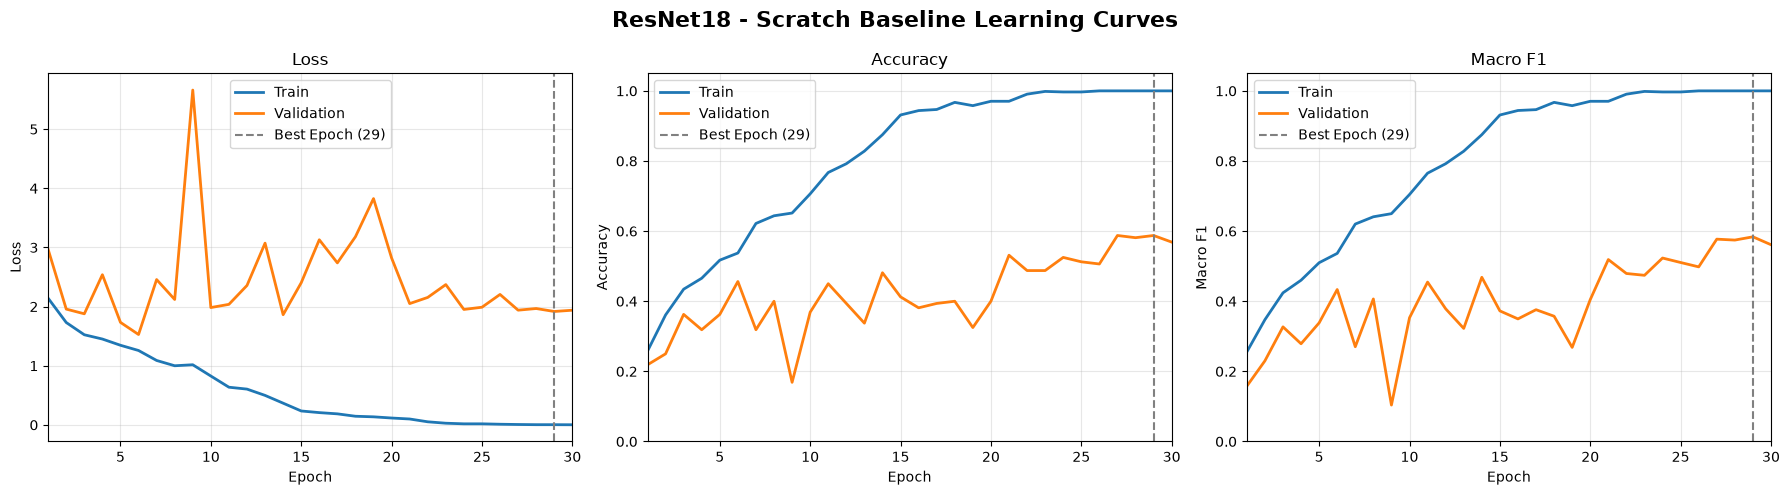

Figure Saved: c:\Users\yunha\human-action-classification\figures\scratch_baseline_learning_curves.png


In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [
    ("loss", "Loss"),
    ("accuracy", "Accuracy"),
    ("f1", "Macro F1")
]

for ax, (metric, title) in zip(axes, metrics):

    # Train 학습 곡선
    ax.plot(
        history_df["epoch"],
        history_df[f"train_{metric}"],
        label="Train",
        linewidth=2
    )

    # Validation 학습 곡선
    ax.plot(
        history_df["epoch"],
        history_df[f"val_{metric}"],
        label="Validation",
        linewidth=2
    )

    # 최적 Epoch 표시
    ax.axvline(
        x=best_epoch,
        color="gray",
        linestyle="--",
        label=f"Best Epoch ({best_epoch})"
    )

    # 그래프 설정
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_xlim(1, EPOCHS)
    ax.grid(alpha=0.3)
    ax.legend()

    # Accuracy와 F1의 범위 통일
    if metric != "loss":
        ax.set_ylim(0, 1.05)

fig.suptitle(
    "ResNet18 - Scratch Baseline Learning Curves",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

# 그래프 저장
LEARNING_CURVE_PATH = (
    FIGURE_DIR / f"{EXPERIMENT_NAME}_learning_curves.png"
)

fig.savefig(
    LEARNING_CURVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure Saved:", LEARNING_CURVE_PATH)

## 13. 최적 모델의 Validation 성능 평가

Validation Macro F1 기준으로 선정된 최적 Checkpoint를 불러온다.

Validation 데이터에 대한 예측값과 클래스별 예측 확률을 수집하고,
Accuracy, Macro Precision, Macro Recall, Macro F1을 계산한다.

수집된 예측 결과는 이후 클래스별 성능 평가 및 오류 분석에 활용한다.

In [49]:
# 최적 Checkpoint 불러오기
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

# 동일한 모델 구조 생성
best_model = resnet18(weights=None)
best_model.fc = nn.Linear(
    best_model.fc.in_features,
    NUM_CLASSES
)

# 저장된 모델 상태 불러오기
best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

# GPU 이동 및 평가 모드 설정
best_model = best_model.to(device)
best_model.eval()

print("===== Best Checkpoint Loaded =====")
print("Best Epoch:", checkpoint["epoch"])
print(f"Validation Loss: {checkpoint['val_loss']:.4f}")
print(f"Validation Accuracy: {checkpoint['val_accuracy']:.4f}")
print(f"Validation Macro F1: {checkpoint['val_f1']:.4f}")
print("Model Device:", next(best_model.parameters()).device)
print("Model Training Mode:", best_model.training)

===== Best Checkpoint Loaded =====
Best Epoch: 29
Validation Loss: 1.9176
Validation Accuracy: 0.5875
Validation Macro F1: 0.5837
Model Device: cuda:0
Model Training Mode: False


In [50]:
# 예측 결과 저장용 리스트
all_labels = []
all_preds = []
all_probs = []
all_confidences = []

running_loss = 0.0

# 평가 모드 설정
best_model.eval()

with torch.no_grad():

    for images, labels in val_loader:

        # GPU 이동
        images = images.to(device)
        labels = labels.to(device)

        # 순전파
        logits = best_model(images)

        # Loss 계산
        loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)

        # 클래스별 예측 확률 계산
        probs = torch.softmax(logits, dim=1)

        # 예측 클래스 및 Confidence 추출
        confidences, preds = probs.max(dim=1)

        # 결과 누적
        all_labels.extend(labels.cpu().tolist())
        all_preds.extend(preds.cpu().tolist())
        all_probs.extend(probs.cpu().tolist())
        all_confidences.extend(confidences.cpu().tolist())

# 전체 Validation 평균 Loss
val_loss = running_loss / len(all_labels)

# NumPy 배열로 변환
y_true = np.array(all_labels)
y_pred = np.array(all_preds)
y_probs = np.array(all_probs)
y_confidence = np.array(all_confidences)

print("True Labels Shape:", y_true.shape)
print("Predictions Shape:", y_pred.shape)
print("Probabilities Shape:", y_probs.shape)
print("Confidence Shape:", y_confidence.shape)

True Labels Shape: (160,)
Predictions Shape: (160,)
Probabilities Shape: (160, 8)
Confidence Shape: (160,)


In [51]:
from sklearn.metrics import precision_score, recall_score

# 전체 평가 지표 계산
val_accuracy = accuracy_score(y_true, y_pred)

val_precision = precision_score(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    average="macro",
    zero_division=0
)

val_recall = recall_score(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    average="macro",
    zero_division=0
)

val_f1 = f1_score(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    average="macro",
    zero_division=0
)

# 평가 결과 정리
evaluation_df = pd.DataFrame([{
    "experiment_name": EXPERIMENT_NAME,
    "split": "validation",
    "epoch": checkpoint["epoch"],
    "loss": val_loss,
    "accuracy": val_accuracy,
    "macro_precision": val_precision,
    "macro_recall": val_recall,
    "macro_f1": val_f1
}])

display(evaluation_df.round(4))

,experiment_name,split,epoch,loss,accuracy,macro_precision,macro_recall,macro_f1
0,scratch_baseline,validation,29,1.9176,0.5875,0.5879,0.5875,0.5837


In [52]:
# 저장된 Checkpoint 성능과 재평가 결과 비교
print("===== Checkpoint Verification =====")

print(
    "Loss Match:",
    np.isclose(val_loss, checkpoint["val_loss"])
)

print(
    "Accuracy Match:",
    np.isclose(val_accuracy, checkpoint["val_accuracy"])
)

print(
    "Macro F1 Match:",
    np.isclose(val_f1, checkpoint["val_f1"])
)

===== Checkpoint Verification =====
Loss Match: True
Accuracy Match: True
Macro F1 Match: True


In [53]:
# 평가 결과 저장 경로
EVALUATION_PATH = (
    RESULT_DIR / f"{EXPERIMENT_NAME}_evaluation.csv"
)

# CSV 저장
evaluation_df.to_csv(
    EVALUATION_PATH,
    index=False
)

print("Evaluation Saved:", EVALUATION_PATH)
print("File Exists:", EVALUATION_PATH.exists())

Evaluation Saved: c:\Users\yunha\human-action-classification\results\scratch_baseline_evaluation.csv
File Exists: True


## 14. 클래스별 성능 및 Confusion Matrix 분석

최적 Checkpoint의 Validation 예측 결과를 활용하여
클래스별 Precision, Recall, F1-score를 계산한다.

Confusion Matrix를 통해 주요 혼동 클래스를 파악하고,
향후 오류 분석 및 개선 실험의 근거로 활용한다.

In [54]:
# 클래스 이름 정의 (target_id 순서)
class_names = [
    "Climbing",
    "Jumping",
    "Riding Bike",
    "Riding Horse",
    "Rowing Boat",
    "Running",
    "Shooting Arrow",
    "Throwing Frisbee"
]

# 클래스별 평가 결과
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# DataFrame 변환
report_df = pd.DataFrame(report).T

display(report_df.round(4))

,precision,recall,f1-score,support
Climbing,0.8750,0.7000,0.7778,20.0000
Jumping,0.5238,0.5500,0.5366,20.0000
Riding Bike,0.6667,0.7000,0.6829,20.0000
Riding Horse,0.4286,0.3000,0.3529,20.0000
Rowing Boat,0.8182,0.9000,0.8571,20.0000
Running,0.4500,0.4500,0.4500,20.0000
Shooting Arrow,0.3810,0.4000,0.3902,20.0000
Throwing Frisbee,0.5600,0.7000,0.6222,20.0000
accuracy,0.5875,0.5875,0.5875,0.5875
macro avg,0.5879,0.5875,0.5837,160.0000


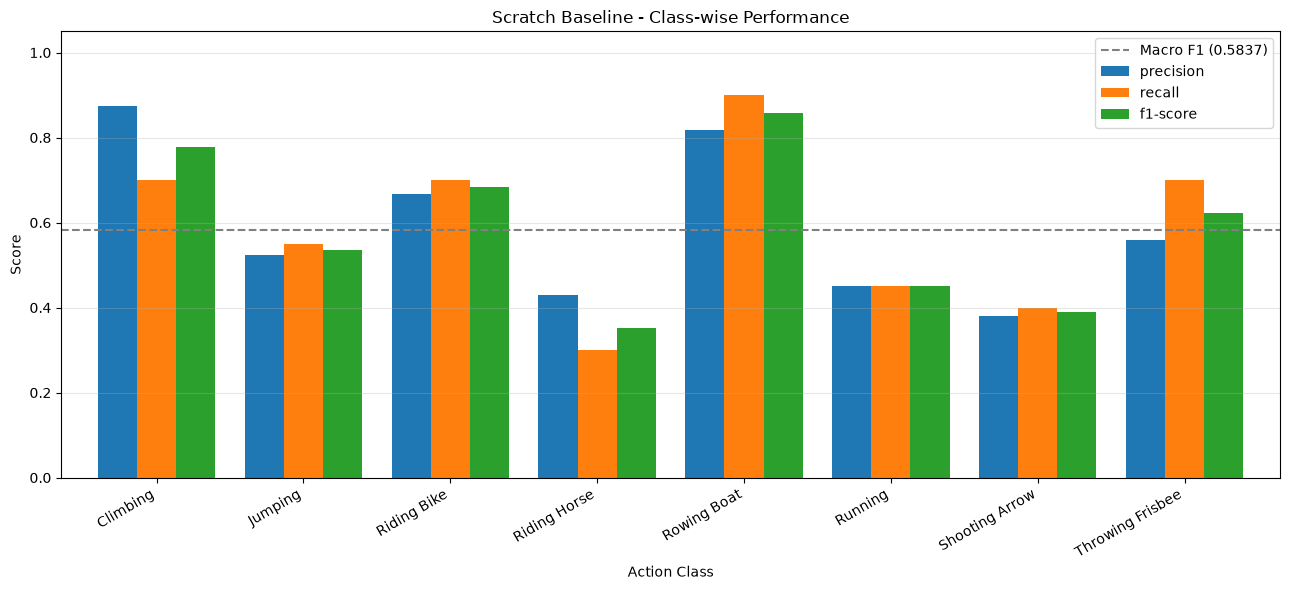

In [55]:
# 클래스별 평가 결과만 추출
class_report_df = report_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
].copy()

# 클래스별 성능 시각화
ax = class_report_df[
    ["precision", "recall", "f1-score"]
].plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title("Scratch Baseline - Class-wise Performance")
ax.set_xlabel("Action Class")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

# 전체 Macro F1 기준선
ax.axhline(
    y=val_f1,
    color="gray",
    linestyle="--",
    label=f"Macro F1 ({val_f1:.4f})"
)

plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

# 그래프 저장
CLASS_METRICS_PATH = (
    FIGURE_DIR / f"{EXPERIMENT_NAME}_class_metrics.png"
)

plt.savefig(
    CLASS_METRICS_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:
# Confusion Matrix 계산
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

# DataFrame 변환
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

display(cm_df)

,Climbing,Jumping,Riding Bike,Riding Horse,Rowing Boat,Running,Shooting Arrow,Throwing Frisbee
Climbing,14,1,1,1,0,0,3,0
Jumping,0,11,0,2,0,4,2,1
Riding Bike,0,0,14,2,1,1,2,0
Riding Horse,1,4,4,6,3,1,1,0
Rowing Boat,0,0,0,1,18,0,1,0
Running,1,5,1,0,0,9,1,3
Shooting Arrow,0,0,0,2,0,3,8,7
Throwing Frisbee,0,0,1,0,0,2,3,14


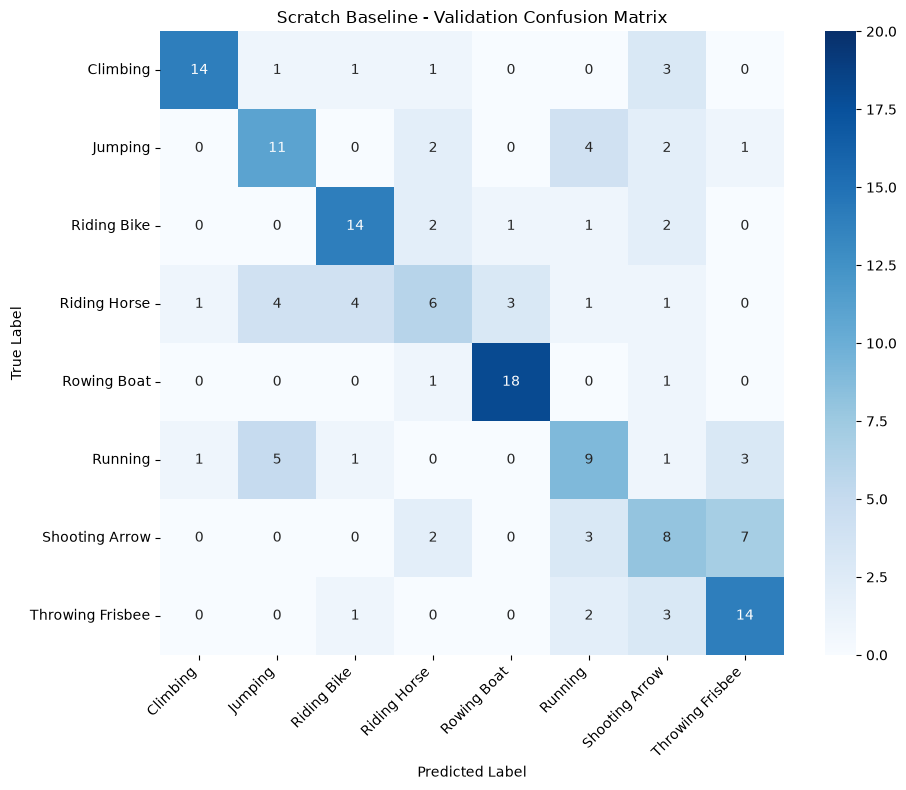

In [57]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    vmin=0,
    vmax=20,
    square=True
)

plt.title("Scratch Baseline - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

# 그래프 저장
CONFUSION_MATRIX_PATH = (
    FIGURE_DIR / f"{EXPERIMENT_NAME}_confusion_matrix.png"
)

plt.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
# 오분류 유형 저장
confusion_records = []

for true_id in range(NUM_CLASSES):
    for pred_id in range(NUM_CLASSES):

        # 정분류 제외
        if true_id == pred_id:
            continue

        # 오분류가 발생한 경우만 기록
        if cm[true_id, pred_id] > 0:

            confusion_records.append({
                "true_class": class_names[true_id],
                "predicted_class": class_names[pred_id],
                "count": cm[true_id, pred_id]
            })

# DataFrame 변환 및 정렬
confusion_pairs_df = (
    pd.DataFrame(confusion_records)
    .sort_values("count", ascending=False)
    .reset_index(drop=True)
)

# 상위 10개 오분류 유형 확인
display(confusion_pairs_df.head(10))

,true_class,predicted_class,count
0,Shooting Arrow,Throwing Frisbee,7
1,Running,Jumping,5
2,Jumping,Running,4
3,Riding Horse,Riding Bike,4
4,Riding Horse,Jumping,4
5,Climbing,Shooting Arrow,3
6,Running,Throwing Frisbee,3
7,Riding Horse,Rowing Boat,3
8,Shooting Arrow,Running,3
9,Throwing Frisbee,Shooting Arrow,3


In [59]:
# 클래스별 평가 결과 저장
class_report_df.to_csv(
    RESULT_DIR / f"{EXPERIMENT_NAME}_class_report.csv",
    index_label="class_name"
)

# Confusion Matrix 저장
cm_df.to_csv(
    RESULT_DIR / f"{EXPERIMENT_NAME}_confusion_matrix.csv",
    index_label="true_class"
)

# 오분류 유형 저장
confusion_pairs_df.to_csv(
    RESULT_DIR / f"{EXPERIMENT_NAME}_confusion_pairs.csv",
    index=False
)

print("Class-wise Analysis Results Saved")

Class-wise Analysis Results Saved


## 15. Scratch 기준선 결과 해석

### 15.1 전체 성능

ResNet18 모델을 사전학습 가중치 없이 초기화하여 30 Epoch 동안 학습하였다.

- Best Epoch: 29
- Validation Accuracy: 0.5875
- Validation Macro Precision: 0.5879
- Validation Macro Recall: 0.5875
- Validation Macro F1: 0.5837
- 전체 학습 소요 시간: 99.90초
- 학습 가능 파라미터 수: 11,180,616개

### 15.2 학습 곡선 분석

Train Loss는 학습이 진행됨에 따라 지속적으로 감소하였으며, 26 Epoch부터 Train Accuracy와 Macro F1이 1.0에 도달하였다.

반면 Validation 성능은 학습 과정에서 큰 변동을 보였으며, 최적 Epoch에서 Train과 Validation의 Macro F1 차이는 0.4163으로 나타났다.

이를 통해 학습 데이터에 대한 적합은 충분히 이루어졌으나 일반화 성능에는 개선이 필요하며, 과적합 양상이 나타났음을 확인하였다.

다만 학습 후반부에도 Validation 성능이 추가로 향상되었으므로, 단순히 학습 Epoch를 감소시키는 것이 효과적인지는 추가 실험을 통해 검증할 필요가 있다.

### 15.3 클래스별 성능 분석

보트 노 젓기(F1: 0.8571), 등반(F1: 0.7778), 자전거 타기(F1: 0.6829)에서 상대적으로 높은 성능을 기록하였다.

반면 승마(F1: 0.3529), 활쏘기(F1: 0.3902), 달리기(F1: 0.4500)에서 낮은 성능을 기록하였다.

세 클래스에서 발생한 오분류는 총 37건으로, 전체 오분류 66건의 약 56.1%를 차지하였다.

### 15.4 주요 혼동 유형

Confusion Matrix 분석 결과 다음과 같은 주요 혼동 유형이 확인되었다.

- 활쏘기와 프리스비 던지기 간 상호 혼동: 10건
- 점프와 달리기 간 상호 혼동: 9건
- 승마 이미지의 자전거 타기, 점프, 보트 노 젓기 등 여러 클래스에 대한 분산된 오분류

이러한 혼동은 행동 자세의 유사성, 운동 도구의 가시성, 인물 및 주변 물체의 특징 학습 부족 등과 관련되어 있을 가능성이 있다.

다만 구체적인 오류 원인은 실제 이미지 검토 및 추가 분석을 통해 검증해야 한다.

### 15.5 향후 실험 방향

현재 Scratch 모델의 결과를 기준선으로 유지하고, 동일한 데이터 분할과 초기 전처리 조건에서 Feature Extraction 및 Fine-tuning 모델을 학습한다.

학습 전략별 전체 성능, 클래스별 성능, 학습 효율 및 오류 패턴을 비교하여 사전학습 가중치 활용에 따른 성능 변화를 확인한다.

이후 대표적인 오분류 사례와 정분류 사례를 비교하고, VLM 기반 이미지 분석을 보조적으로 활용하여 추가 개선 가설을 수립한다.

현재 결과는 단일 Seed의 Validation 평가 결과이며, Test 데이터에 대한 일반화 성능은 아직 확인하지 않았다.